### Main file of the task 2: Image Denoising

In [1]:
import torch
from datasets import DenoiseDataset
from torch.utils.data import DataLoader, random_split
from models import DenoiseNet
from loss import MseSsimLipsLoss
import torch.optim as optim
from tqdm import tqdm
import matplotlib.pyplot as plt
import cv2
from torchvision import transforms
from metrics import evaluate_model, print_results_table, bilateral_image
from torchmetrics.image import StructuralSimilarityIndexMeasure
import numpy as np

Make sure to run `prepare_data.py` once to prepare the images.

In [2]:
DATA_PATH = "C:/Users/zuzu/Desktop/sigk-main-lab1/data/DIV2K_train_256"

In [3]:
def prepareDevice():
    import os
    os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
    
    device = torch.device("cpu")

    if torch.cuda.is_available():
        device = torch.device("cuda")
        torch.cuda.manual_seed(42)
        torch.cuda.manual_seed_all(42)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        print("Using CUDA")
    else:
        print("Using CPU")

    return device

In [4]:
DEVICE = prepareDevice()

import gc

def reset_cuda():
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()

reset_cuda()

BATCH_SIZE = 16
LEARNING_RATE = 0.0005
NUM_EPOCHS = 5

Using CUDA


In [5]:
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            total_loss += loss.item()
    avg_loss = total_loss / len(loader)
    return avg_loss

In [6]:
def train(model, train_dataloader, val_dataloader, criterion, optimizer, model_name="model"):
    best_val_loss = float("inf")

    for epoch in range(NUM_EPOCHS):
        model.train()
        running_loss = 0.0
        for _, (inputs, targets) in enumerate(tqdm(train_dataloader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS}")):
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        
        avg_train_loss = running_loss / len(train_dataloader)
        avg_val_loss = evaluate(model, val_dataloader, criterion)

        print(f"Epoch {epoch+1}/{NUM_EPOCHS} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

        if avg_val_loss < best_val_loss:
            torch.save(model.state_dict(), model_name + ".pth")
            best_val_loss = avg_val_loss

        # cleanup per epoch to minimize fragmentation and avoid OOM
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        gc.collect()


### For sigma 0.01

In [7]:
SIGMA = 0.01
DATA_PATH = "C:/Users/zuzu/Desktop/sigk-main-lab1/data/DIV2K_train_256"
dataset = DenoiseDataset(DATA_PATH, sigma=SIGMA)
train_size = int(0.7 * len(dataset))
val_size = len(dataset) - train_size
print(f"Dataset size: {len(dataset)}, Train size: {train_size}, Val size: {val_size}")
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])
train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_dataloader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
model = DenoiseNet().to(DEVICE)
criterion = MseSsimLipsLoss(device=DEVICE)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

Dataset size: 800, Train size: 560, Val size: 240
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


c:\Users\zuzu\AppData\Local\Programs\Python\Python39\lib\site-packages\torch\nn\modules\module.py:1326: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\c10/cuda/CUDAAllocatorConfig.h:28.)
  return t.to(
c:\Users\zuzu\AppData\Local\Programs\Python\Python39\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\zuzu\AppData\Local\Programs\Python\Python39\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: c:\Users\zuzu\AppData\Local\Programs\Python\Python39\lib\site-packages\lpips\weights\v0.1\alex.pth


c:\Users\zuzu\AppData\Local\Programs\Python\Python39\lib\site-packages\lpips\lpips.py:107: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(mode

In [8]:
train(model, train_dataloader, val_dataloader, criterion, optimizer, "denoise_001")

Epoch 1/5: 100%|██████████| 35/35 [15:41<00:00, 26.89s/it]


Epoch 1/5 | Train Loss: 0.0695 | Val Loss: 0.1325


Epoch 2/5: 100%|██████████| 35/35 [13:40<00:00, 23.44s/it]


Epoch 2/5 | Train Loss: 0.0287 | Val Loss: 0.0224


Epoch 3/5: 100%|██████████| 35/35 [12:59<00:00, 22.28s/it]


Epoch 3/5 | Train Loss: 0.0228 | Val Loss: 0.0165


Epoch 4/5: 100%|██████████| 35/35 [12:23<00:00, 21.25s/it]


Epoch 4/5 | Train Loss: 0.0193 | Val Loss: 0.0142


Epoch 5/5: 100%|██████████| 35/35 [12:51<00:00, 22.04s/it]


Epoch 5/5 | Train Loss: 0.0202 | Val Loss: 0.0164


C:\Users\zuzu\AppData\Local\Temp\ipykernel_13444\2243487210.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("denoise_001.pth"))


Noisy shape: torch.Size([1, 3, 256, 256]), Output shape: torch.Size([1, 3, 256, 256]), Clean shape: torch.Size([1, 3, 256, 256])


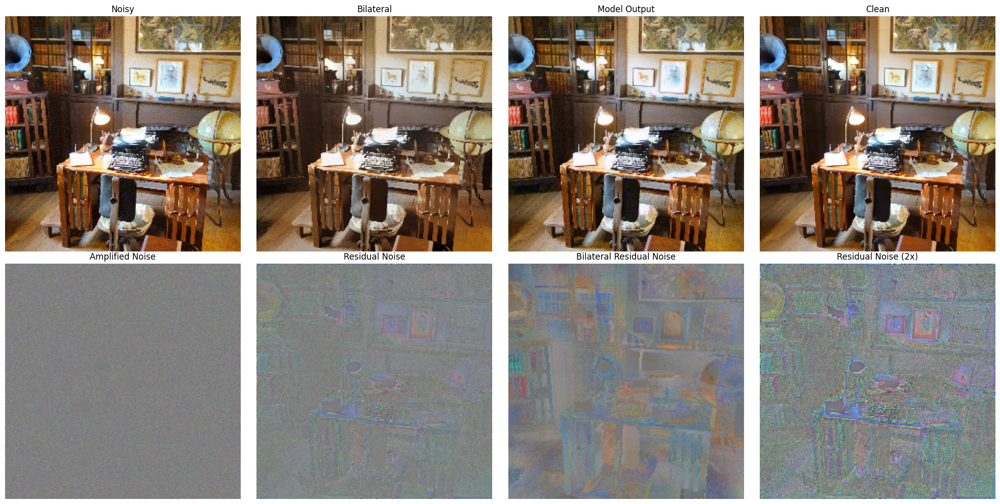

In [24]:
#An example
noisy_tensor, clean_tensor = val_dataset[0]  
noisy_tensor = noisy_tensor.unsqueeze(0).to(DEVICE)  
clean_tensor = clean_tensor.unsqueeze(0).to(DEVICE)
model = DenoiseNet().to(DEVICE)
model.load_state_dict(torch.load("denoise_001.pth"))
model.eval()
with torch.no_grad():
    output_tensor = model(noisy_tensor)
print(f"Noisy shape: {noisy_tensor.shape}, Output shape: {output_tensor.shape}, Clean shape: {clean_tensor.shape}")
def tensor_to_img(tensor):
    img = tensor.squeeze(0).cpu().permute(1,2,0).numpy()
    img = np.clip(img, 0, 1)
    return img
noisy_np = tensor_to_img(noisy_tensor)
output_np = tensor_to_img(output_tensor)
clean_np = tensor_to_img(clean_tensor)

bilateral_np = bilateral_image(noisy_tensor.cpu()).squeeze(0).permute(1,2,0).numpy()

fig, axes = plt.subplots(2, 4, figsize=(20,10))

# --- First row ---
axes[0,0].imshow(noisy_np);      axes[0,0].set_title("Noisy")
axes[0,1].imshow(bilateral_np);  axes[0,1].set_title("Bilateral")
axes[0,2].imshow(output_np);     axes[0,2].set_title("Model Output")
axes[0,3].imshow(clean_np);      axes[0,3].set_title("Clean")

# --- Compute differences ---
diff = np.clip((noisy_np - clean_np) + 0.5, 0, 1)
residual = np.clip((output_np - clean_np) + 0.5, 0, 1)

diff2 = np.clip((bilateral_np - clean_np) + 0.5, 0, 1)
residual2 = np.clip((output_np - clean_np)*2 + 0.5, 0, 1)

# --- Second row ---
axes[1,0].imshow(diff);      axes[1,0].set_title("Amplified Noise")
axes[1,1].imshow(residual);  axes[1,1].set_title("Residual Noise")
axes[1,2].imshow(diff2);     axes[1,2].set_title("Bilateral Residual Noise")
axes[1,3].imshow(residual2); axes[1,3].set_title("Residual Noise (2x)")

# --- Clean up axes ---
for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()
plt.show()

### For sigma 0.03

In [11]:
SIGMA_03 = 0.03
dataset = DenoiseDataset(DATA_PATH, sigma=SIGMA_03)
train_size = int(0.7 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])
train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_dataloader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
model = DenoiseNet().to(DEVICE)
criterion = MseSsimLipsLoss(device=DEVICE)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Loading model from: c:\Users\zuzu\AppData\Local\Programs\Python\Python39\lib\site-packages\lpips\weights\v0.1\alex.pth


In [12]:
train(model, train_dataloader, val_dataloader, criterion, optimizer, model_name="denoise_003")

Epoch 1/5: 100%|██████████| 35/35 [17:05<00:00, 29.31s/it]


Epoch 1/5 | Train Loss: 0.0769 | Val Loss: 0.1223


Epoch 2/5: 100%|██████████| 35/35 [13:42<00:00, 23.49s/it]


Epoch 2/5 | Train Loss: 0.0365 | Val Loss: 0.0301


Epoch 3/5: 100%|██████████| 35/35 [11:40<00:00, 20.01s/it]


Epoch 3/5 | Train Loss: 0.0297 | Val Loss: 0.0249


Epoch 4/5: 100%|██████████| 35/35 [13:39<00:00, 23.41s/it]


Epoch 4/5 | Train Loss: 0.0286 | Val Loss: 0.0305


Epoch 5/5: 100%|██████████| 35/35 [13:03<00:00, 22.38s/it]


Epoch 5/5 | Train Loss: 0.0251 | Val Loss: 0.0225


Noisy shape: torch.Size([1, 3, 256, 256]), Output shape: torch.Size([1, 3, 256, 256]), Clean shape: torch.Size([1, 3, 256, 256])


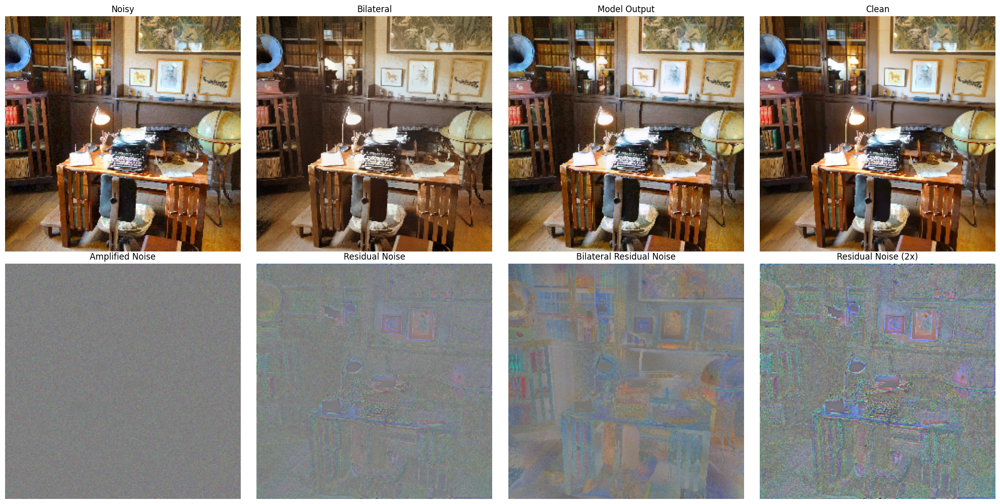

In [25]:
#An example
noisy_tensor, clean_tensor = val_dataset[0]  
noisy_tensor = noisy_tensor.unsqueeze(0).to(DEVICE)  
clean_tensor = clean_tensor.unsqueeze(0).to(DEVICE)
# model = DenoiseNet().to(DEVICE)
# model.load_state_dict(torch.load("denoise_003.pth"))
model.eval()
with torch.no_grad():
    output_tensor = model(noisy_tensor)
print(f"Noisy shape: {noisy_tensor.shape}, Output shape: {output_tensor.shape}, Clean shape: {clean_tensor.shape}")
def tensor_to_img(tensor):
    img = tensor.squeeze(0).cpu().permute(1,2,0).numpy()
    img = np.clip(img, 0, 1)
    return img
noisy_np = tensor_to_img(noisy_tensor)
output_np = tensor_to_img(output_tensor)
clean_np = tensor_to_img(clean_tensor)

bilateral_np = bilateral_image(noisy_tensor.cpu()).squeeze(0).permute(1,2,0).numpy()

fig, axes = plt.subplots(2, 4, figsize=(20,10))

# --- First row ---
axes[0,0].imshow(noisy_np);      axes[0,0].set_title("Noisy")
axes[0,1].imshow(bilateral_np);  axes[0,1].set_title("Bilateral")
axes[0,2].imshow(output_np);     axes[0,2].set_title("Model Output")
axes[0,3].imshow(clean_np);      axes[0,3].set_title("Clean")

# --- Compute differences ---
diff = np.clip((noisy_np - clean_np) + 0.5, 0, 1)
residual = np.clip((output_np - clean_np) + 0.5, 0, 1)

diff2 = np.clip((bilateral_np - clean_np) + 0.5, 0, 1)
residual2 = np.clip((output_np - clean_np)*2 + 0.5, 0, 1)

# --- Second row ---
axes[1,0].imshow(diff);      axes[1,0].set_title("Amplified Noise")
axes[1,1].imshow(residual);  axes[1,1].set_title("Residual Noise")
axes[1,2].imshow(diff2);     axes[1,2].set_title("Bilateral Residual Noise")
axes[1,3].imshow(residual2); axes[1,3].set_title("Residual Noise (2x)")

# --- Clean up axes ---
for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()
plt.show()

# Calculating metrics

In [17]:
VALIDATION_DATA_PATH = "C:/Users/zuzu/Desktop/sigk-main-lab1/data/DIV2K_valid_256"
dataset_001 = DenoiseDataset(VALIDATION_DATA_PATH, sigma=0.01)
dataset_003 = DenoiseDataset(VALIDATION_DATA_PATH, sigma=0.03)
model_001 = DenoiseNet().to(DEVICE)
model_001.load_state_dict(torch.load("denoise_001.pth"))
model_003 = DenoiseNet().to(DEVICE)
model_003.load_state_dict(torch.load("denoise_003.pth"))
results_001 = evaluate_model(model_001, dataset_001, bilateral_image, "Bilateral", DEVICE)
results_003 = evaluate_model(model_003, dataset_003, bilateral_image, "Bilateral", DEVICE)

C:\Users\zuzu\AppData\Local\Temp\ipykernel_13444\3897927892.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_001.load_state_dict(torch.load("denoise_001.pth"))
C:\U

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Loading model from: c:\Users\zuzu\AppData\Local\Programs\Python\Python39\lib\site-packages\lpips\weights\v0.1\alex.pth


c:\Users\zuzu\AppData\Local\Programs\Python\Python39\lib\site-packages\torchmetrics\utilities\prints.py:70: FutureWarning: Importing `peak_signal_noise_ratio` from `torchmetrics.functional` was deprecated and will be removed in 2.0. Import `peak_signal_noise_ratio` from `torchmetrics.image` instead.
  _future_warning(


Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Loading model from: c:\Users\zuzu\AppData\Local\Programs\Python\Python39\lib\site-packages\lpips\weights\v0.1\alex.pth


In [18]:
print_results_table(results_001, "Denoising σ=0.01", "Bilateral")
print_results_table(results_003, "Denoising σ=0.03", "Bilateral")


Denoising σ=0.01
Method                          PSNR       SSIM      LPIPS        SNE
----------------------------------------------------------------------
Bilateral denoising            27.57     0.9202     0.0819      15.21
Model                          28.60     0.9449     0.0225      16.91

Denoising σ=0.03
Method                          PSNR       SSIM      LPIPS        SNE
----------------------------------------------------------------------
Bilateral denoising            27.32     0.9065     0.0828      14.95
Model                          26.87     0.9125     0.0376      15.18


### σ=0.01 examples

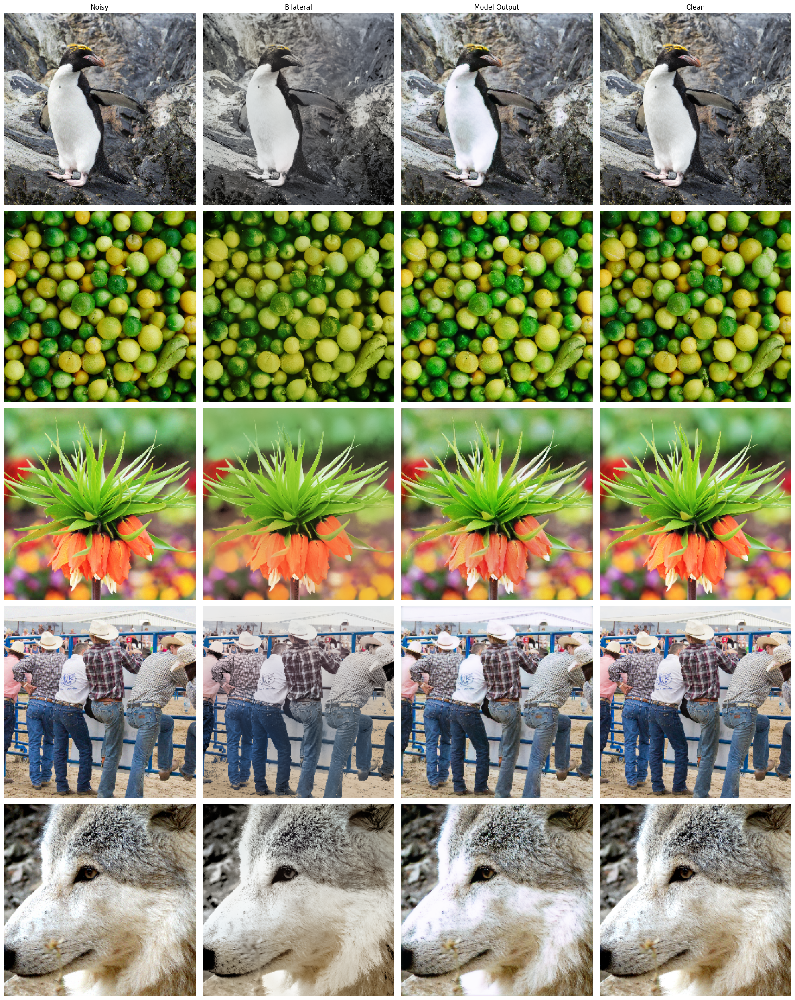

In [20]:
model_001.eval()

fig, axes = plt.subplots(5, 4, figsize=(20, 25))
for i in range(5):
    noisy_tensor, clean_tensor = dataset_001[i]
    
    noisy_tensor = noisy_tensor.unsqueeze(0).to(DEVICE)
    clean_tensor = clean_tensor.unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        output_tensor = model_001(noisy_tensor)

    def tensor_to_img(tensor):
        img = tensor.squeeze(0).cpu().permute(1,2,0).numpy()
        img = np.clip(img, 0, 1)
        return img

    noisy_np = tensor_to_img(noisy_tensor)
    output_np = tensor_to_img(output_tensor)
    clean_np = tensor_to_img(clean_tensor)

    bilateral_np = bilateral_image(noisy_tensor.cpu()).squeeze(0).permute(1,2,0).numpy()

    axes[i, 0].imshow(noisy_np)
    axes[i, 1].imshow(bilateral_np)
    axes[i, 2].imshow(output_np)
    axes[i, 3].imshow(clean_np)

    if i == 0:
        axes[i, 0].set_title("Noisy")
        axes[i, 1].set_title("Bilateral")
        axes[i, 2].set_title("Model Output")
        axes[i, 3].set_title("Clean")

    for j in range(4):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

### σ=0.03 examples

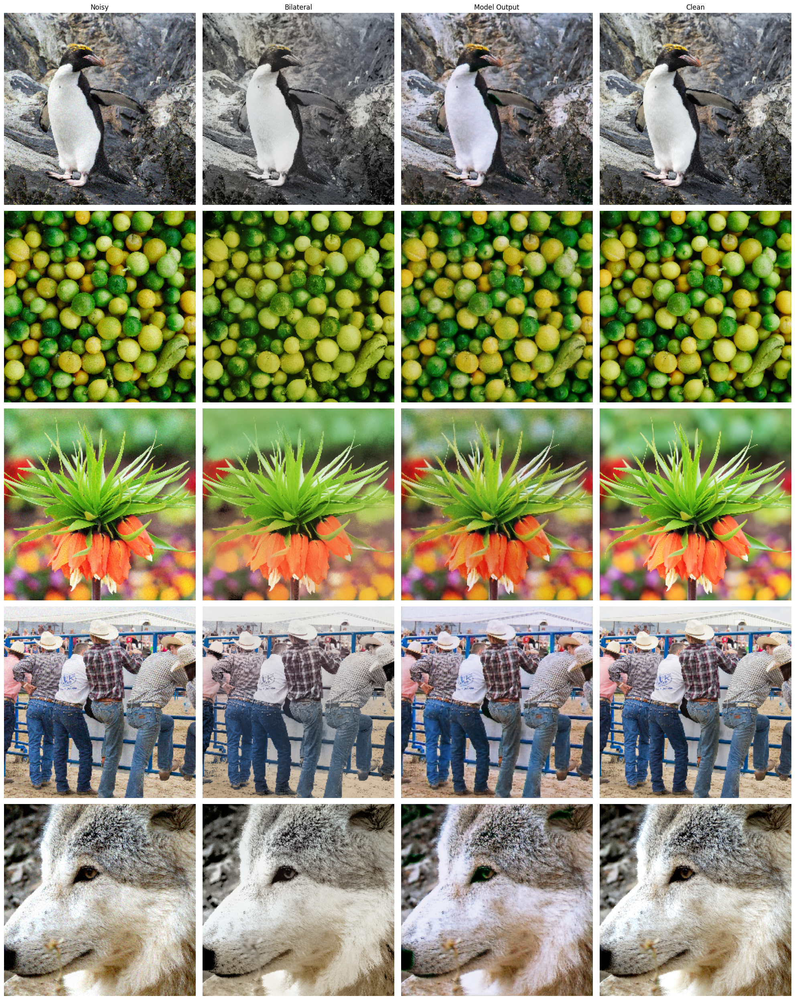

In [21]:
model_003.eval()

fig, axes = plt.subplots(5, 4, figsize=(20, 25))
for i in range(5):
    noisy_tensor, clean_tensor = dataset_003[i]
    
    noisy_tensor = noisy_tensor.unsqueeze(0).to(DEVICE)
    clean_tensor = clean_tensor.unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        output_tensor = model_003(noisy_tensor)

    def tensor_to_img(tensor):
        img = tensor.squeeze(0).cpu().permute(1,2,0).numpy()
        img = np.clip(img, 0, 1)
        return img

    noisy_np = tensor_to_img(noisy_tensor)
    output_np = tensor_to_img(output_tensor)
    clean_np = tensor_to_img(clean_tensor)

    bilateral_np = bilateral_image(noisy_tensor.cpu()).squeeze(0).permute(1,2,0).numpy()

    axes[i, 0].imshow(noisy_np)
    axes[i, 1].imshow(bilateral_np)
    axes[i, 2].imshow(output_np)
    axes[i, 3].imshow(clean_np)

    if i == 0:
        axes[i, 0].set_title("Noisy")
        axes[i, 1].set_title("Bilateral")
        axes[i, 2].set_title("Model Output")
        axes[i, 3].set_title("Clean")

    for j in range(4):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()